# Soluciones de la Tareas de la Práctica 4

Este cuaderno realiza lo siguiente:
1. Detector de matrículas **YOLO11n** (se reutiliza el ya entrenado si existe) y **YOLO vs RT-DETR** (mismas imágenes y condiciones, comparando métricas, coste, fotos propias y recortes del vídeo)
2. **Comparativa de OCR**: EasyOCR (clásico) frente a SmolVLM (VLM), más una variante de EasyOCR que se queda sólo con las letras grandes.
3. **Prototipo de vídeo**: seguimiento, matrículas, **lectura por votación entre varios recortes y varios OCR**, conteo, **flujo con corrección de perspectiva** (la cámara está en medio de la carretera: los coches *se acercan* o *se alejan*), CSV, vídeo y **vídeo anonimizado**.
4. **Validación manual** de las lecturas del vídeo, para medir el acierto real en recortes borrosos.

---
_Se ha ejecutado varias veces, por lo que hay archivos ya creados de antes._

## Preparación

In [1]:
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/VC_P4")
    WORK = Path("/content/work")
else:
    BASE = Path(".")
    WORK = Path("work")

WORK.mkdir(parents=True, exist_ok=True)
os.chdir(BASE)
print("Carpeta de trabajo:", Path.cwd())
print("Contenido:", sorted(p.name for p in Path.cwd().iterdir())[:20])

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/VC_P4
Contenido: ['C0142.MP4', 'P4_Tareas.ipynb', 'VC_P4.ipynb', 'dataset_manifiesto.csv', 'imagenes', 'ocr_dataset', 'resultado.csv', 'resultado.mp4', 'resultado_anonimizado.mp4', 'resultado_anonimizado_comprimido.mp4', 'resultado_comprimido.mp4', 'resultados', 'rtdetr-l.pt', 'runs', 'yolo11n.pt']


In [2]:
paquetes = ["ultralytics", "kagglehub", "easyocr", "transformers", "accelerate", "pandas", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *paquetes], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'ultralytics', 'kagglehub', 'easyocr', 'transformers', 'accelerate', 'pandas', 'matplotlib'], returncode=0)

In [3]:
import cv2, re, json, random, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from collections import Counter, defaultdict
from ultralytics import YOLO, RTDETR

USA_GPU = torch.cuda.is_available()
DEVICE = 0 if USA_GPU else "cpu"

# especificaciones de la máquina
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("GPU         :", torch.cuda.get_device_name(0) if USA_GPU else "NO (CPU)  -> Entorno > Cambiar tipo de entorno > T4 GPU")
print("CPU         :", platform.processor() or platform.machine())
try:
    import psutil
    print("RAM         :", round(psutil.virtual_memory().total / 1e9, 1), "GB")
except ImportError:
    pass

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python      : 3.13.16
PyTorch     : 2.14.1+cu130
GPU         : Tesla T4
CPU         : x86_64
RAM         : 13.6 GB


### Configuración

In [4]:
# qué ejecutar
HACER_EXTRA_RTDETR = True # extra: entrenar RT-DETR-L y compararlo con YOLO
ENTRENAR_RTDETR = False # se reutiliza runs/rtdetr_matriculas
ENTRENAR_YOLO = None # None=sólo si no existe ya runs/detector_matriculas; True/False para forzar
DETECTOR_MATRICULAS = "auto" # "YOLO11n", "RT-DETR-L" o "auto" (el de mayor mAP50-95 en validación)
DETECTOR_RECORTES_OCR = "YOLO11n" # detector con el que se generan los recortes de OCR
ANONIMIZAR = True # extra: segundo vídeo con personas y matrículas desenfocadas
MODO_ANON = "partes" # "partes" =30 % superior de las personas (cabeza)+matrículas; "completo"=personas y vehículos enteros

VIDEO = BASE / "C0142.MP4"
DIR_PROPIAS = BASE / "imagenes"

# dataset de kaggle
KAGGLE_SLUG = "fareselmenshawii/license-plate-dataset"
DIR_KAGGLE = BASE / "kaggle_raw"
N_KAGGLE_TRAIN = 1500 # sólo se usan si no existe dataset_manifiesto.csv
N_KAGGLE_VAL = 300
DATASET = WORK / "dataset"
YAML = WORK / "dataset.yaml"

# entrenamiento (mismas condiciones para todos los modelos)
EPOCHS = 40
IMGSZ = 640
SEED = 42
BATCH_YOLO = 16 if USA_GPU else 4
BATCH_RTDETR = 8

# vídeo
MODELO_GENERAL = "yolo11n.pt"
TRACKER = "botsort.yaml" # o "bytetrack.yaml"
TRACKER_OVERRIDES = {} # por ej: {"new_track_thresh": 0.5} reduce los identificadores nuevos de objetos lejanos
CLASES = {0: "persona", 1: "bicicleta", 2: "coche", 3: "moto", 5: "autobus", 7: "camion"}
CLASE_PERSONA = 0
VEHICULOS = {1, 2, 3, 5, 7}
CONF = 0.3 # confianza mínima de la detección general
CONF_MAT = 0.3 # confianza mínima de la matrícula
MARGEN_VEH = 0.10 # margen alrededor del vehículo al recortarlo para buscar la matrícula
ALTO_MIN_VEHICULO = 60 # no se busca matrícula en vehículos de menos de 60 px de alto
SALTO = 1 if USA_GPU else 3 # procesa 1 de cada N fotogramas
LIMITE = None # p. ej. 300 para pruebas rápidas; None = vídeo completo

# qué tracks cuentan como objeto real
MIN_FRAMES = max(5, 15 // SALTO) # fotogramas mínimos del track
MIN_ALTO_REL = 0.05 # los objetos muy lejanos (caja < 5% del alto del fotograma) se fragmentan y no se cuentan

# movimiento
ESCALA_CAMBIO = 1.4 # altura de la caja ×1,4 -> "se acerca"; ÷1,4 -> "se aleja"
MIN_MOV_PERSONA = 0.05 # desplazamiento mínimo del centro (proporción del ancho) para no ser "parado"
MIN_MOV_VEHICULO = 0.10

# OCR
OCR_COMPARAR = ["easyocr", "easyocr_filtrado", "smolvlm"]
OCR_VIDEO = ["smolvlm", "easyocr_filtrado"] # motores que votan en el vídeo
K_RECORTES = 5 # mejores recortes de matrícula por vehículo
MIN_VOTOS = 2 # votos mínimos para aceptar una lectura
POSTPROCESO_ES = True

random.seed(SEED)
(BASE / "resultados").mkdir(exist_ok=True)

## Qué hay ya entrenado y qué hay que hacer luego

In [5]:
def ultimo_run(prefijo):
    """Carpeta del entrenamiento más reciente cuyo nombre empieza por `prefijo` (esté donde esté dentro de runs/)"""
    cands = [p.parent for p in (BASE / "runs").rglob("results.csv") if p.parent.name.startswith(prefijo)]
    return max(cands, key=lambda d: (d / "results.csv").stat().st_mtime) if cands else None

RUN_YOLO = ultimo_run("detector_matriculas")
RUN_RTDETR = ultimo_run("rtdetr_matriculas")

entrenar_yolo = ENTRENAR_YOLO if ENTRENAR_YOLO is not None else RUN_YOLO is None
entrenar_rt = HACER_EXTRA_RTDETR and ENTRENAR_RTDETR
hay_extra = HACER_EXTRA_RTDETR and (entrenar_rt or RUN_RTDETR is not None)
necesita_dataset = entrenar_yolo or hay_extra

print("YOLO11n ya entrenado :", RUN_YOLO, "-> se reentrena" if entrenar_yolo else "-> se reutiliza")
print("RT-DETR-L            :", RUN_RTDETR, "-> se entrena" if entrenar_rt else "")
print("¿Hace falta el dataset de Kaggle?:", necesita_dataset)

YOLO11n ya entrenado : /content/drive/MyDrive/VC_P4/runs/detector_matriculas-2 -> se reutiliza
RT-DETR-L            : /content/drive/MyDrive/VC_P4/runs/rtdetr_matriculas 
¿Hace falta el dataset de Kaggle?: True


### Dataset (sólo si hace falta)
Si existe `dataset_manifiesto.csv` se **reconstruye exactamente igual** (mismas imágenes que en tu entrenamiento de YOLO); si no, se muestrea al azar y se guarda el manifiesto.

In [6]:
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def split_de(ruta, raiz):
    partes = [p.lower() for p in ruta.relative_to(raiz).parts]
    for clave, nombre in (("train", "train"), ("val", "val"), ("valid", "val"), ("test", "test")):
        if clave in partes:
            return nombre
    return None

def pares_kaggle(raiz):
    """{split: [(imagen, etiqueta.txt)]}, emparejando por nombre dentro de cada split"""
    raiz = Path(raiz)
    etiquetas = {}
    for t in raiz.rglob("*.txt"):
        if t.name.lower() in {"classes.txt", "labels.txt"}:
            continue
        etiquetas[(split_de(t, raiz), t.stem)] = t
    pares = defaultdict(list)
    for im in raiz.rglob("*"):
        if im.suffix.lower() in EXT:
            s = split_de(im, raiz)
            lbl = etiquetas.get((s, im.stem))
            if lbl is not None:
                pares[s].append((im, lbl))
    return pares

def _fmt(xc, yc, w, h):
    c = lambda v: min(max(v, 0.0), 1.0)
    return f"0 {c(xc):.6f} {c(yc):.6f} {c(w):.6f} {c(h):.6f}"

def lineas_yolo(txt):
    """.txt YOLO (caja, caja+confianza o polígono) -> cajas de clase 0"""
    salida = []
    for linea in Path(txt).read_text().splitlines():
        t = linea.split()
        if len(t) < 5:
            continue
        try:
            v = [float(x) for x in t[1:]]
        except ValueError:
            continue
        if len(v) in (4, 5):
            xc, yc, w, h = v[:4]
        elif len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            xc, yc, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        else:
            continue
        salida.append(_fmt(xc, yc, w, h))
    return salida

def lineas_propias(json_path, W, H):
    """JSON: [{'rectangle': [xc, yc, w, h]}] (normalizado o píxeles) o formato labelme"""
    datos = json.load(open(json_path, encoding="utf-8"))
    salida = []
    if isinstance(datos, dict) and "shapes" in datos:
        for s in datos["shapes"]:
            xs = [p[0] for p in s["points"]]
            ys = [p[1] for p in s["points"]]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            salida.append(_fmt((x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H))
    else:
        for a in datos:
            xc, yc, w, h = map(float, a["rectangle"])
            if max(xc, yc, w, h) > 1.5:
                xc, w, yc, h = xc / W, w / W, yc / H, h / H
            salida.append(_fmt(xc, yc, w, h))
    return salida

def escribir_par(img_path, lineas, split, origen, manifiesto):
    nombre = f"{origen}_{img_path.name}"
    (DATASET / split / "images").mkdir(parents=True, exist_ok=True)
    (DATASET / split / "labels").mkdir(parents=True, exist_ok=True)
    shutil.copy2(img_path, DATASET / split / "images" / nombre)
    (DATASET / split / "labels" / (Path(nombre).stem + ".txt")).write_text("\n".join(lineas))
    manifiesto.append({"split": split, "origen": origen, "archivo": nombre})

def buscar_anotacion(img_path):
    """Busca el .json o .txt de una foto en labels/ o junto a la propia foto"""
    for carpeta in (DIR_ANOT_PROPIAS, DIR_PROPIAS):
        for ext in (".json", ".txt"):
            p = carpeta / (img_path.stem + ext)
            if p.exists():
                return p
    return None

def anotacion_de(img_path, W, H):
    p = buscar_anotacion(img_path)
    if p is None:
        return None
    return lineas_propias(p, W, H) if p.suffix == ".json" else lineas_yolo(p)

def todas_las_fotos():
    return sorted(p for p in DIR_PROPIAS.iterdir() if p.suffix.lower() in EXT) if DIR_PROPIAS.exists() else []

def fotos_propias():
    """Fotos propias que tienen anotación"""
    return [p for p in todas_las_fotos() if buscar_anotacion(p) is not None]

In [7]:
if necesita_dataset:
    import kagglehub
    DIR_KAGGLE = Path(kagglehub.dataset_download(KAGGLE_SLUG))
    pares = pares_kaggle(DIR_KAGGLE)
    indice = {(s, im.name): (im, lb) for s, lista in pares.items() for im, lb in lista}
    if DATASET.exists():
        shutil.rmtree(DATASET)

    nuevo, faltan = [], 0
    man_csv = BASE / "dataset_manifiesto.csv"
    if man_csv.exists():
        man = pd.read_csv(man_csv)
        man = man[man["origen"] == "kaggle"]
        for _, f in man.iterrows():
            par = indice.get((f["split"], f["archivo"][len("kaggle_"):]))
            if par is None:
                faltan += 1
                continue
            lineas = lineas_yolo(par[1])
            if lineas:
                escribir_par(par[0], lineas, f["split"], "kaggle", nuevo)
        assert faltan == 0, f"Faltan {faltan} imágenes del manifiesto"
    else:
        for split, n in (("train", N_KAGGLE_TRAIN), ("val", N_KAGGLE_VAL)):
            pool = pares.get(split, [])
            usadas = 0
            for im, lb in random.sample(pool, len(pool)):
                if usadas >= n:
                    break
                lineas = lineas_yolo(lb)
                if lineas:
                    escribir_par(im, lineas, split, "kaggle", nuevo)
                    usadas += 1
        pd.DataFrame(nuevo).to_csv(man_csv, index=False)

    YAML.write_text(f"path: {DATASET.resolve().as_posix()}\ntrain: train/images\nval: val/images\nnc: 1\nnames:\n  0: matricula\n")
    print(pd.DataFrame(nuevo).groupby("split").size().to_string())
else:
    print('No hace falta el dataset -> se reutilizan los entrenamientos existentes.')

100%|██████████| 1.54G/1.54G [00:25<00:00, 64.4MB/s]

Extracting files...


split
train    1500
val       300


## Detector de matrículas YOLO11n

In [8]:
if entrenar_yolo:
    YOLO("yolo11n.pt").train(data=str(YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH_YOLO, device=DEVICE, patience=15,
                             seed=SEED, workers=2, project=str(BASE / "runs"), name="detector_matriculas")
if entrenar_rt:
    t0 = time.perf_counter()
    RTDETR("rtdetr-l.pt").train(data=str(YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH_RTDETR, device=DEVICE, patience=15,
                                seed=SEED, workers=2, project=str(BASE / "runs"), name="rtdetr_matriculas")
    print(f"Entrenamiento RT-DETR-L: {(time.perf_counter() - t0) / 60:.1f} min")

RUN_YOLO = ultimo_run("detector_matriculas")
RUN_RTDETR = ultimo_run("rtdetr_matriculas")
MODELOS = {"YOLO11n": ("yolo", RUN_YOLO)}
if hay_extra and RUN_RTDETR is not None:
    MODELOS["RT-DETR-L"] = ("rtdetr", RUN_RTDETR)

def cargar(nombre):
    tipo, run = MODELOS[nombre]
    pesos = str(run / "weights" / "best.pt")
    return RTDETR(pesos) if tipo == "rtdetr" else YOLO(pesos)

for k, (_, d) in MODELOS.items():
    print(f"{k:10s} -> {d}")

YOLO11n    -> /content/drive/MyDrive/VC_P4/runs/detector_matriculas-2
RT-DETR-L  -> /content/drive/MyDrive/VC_P4/runs/rtdetr_matriculas


### Curvas de entrenamiento y tiempo

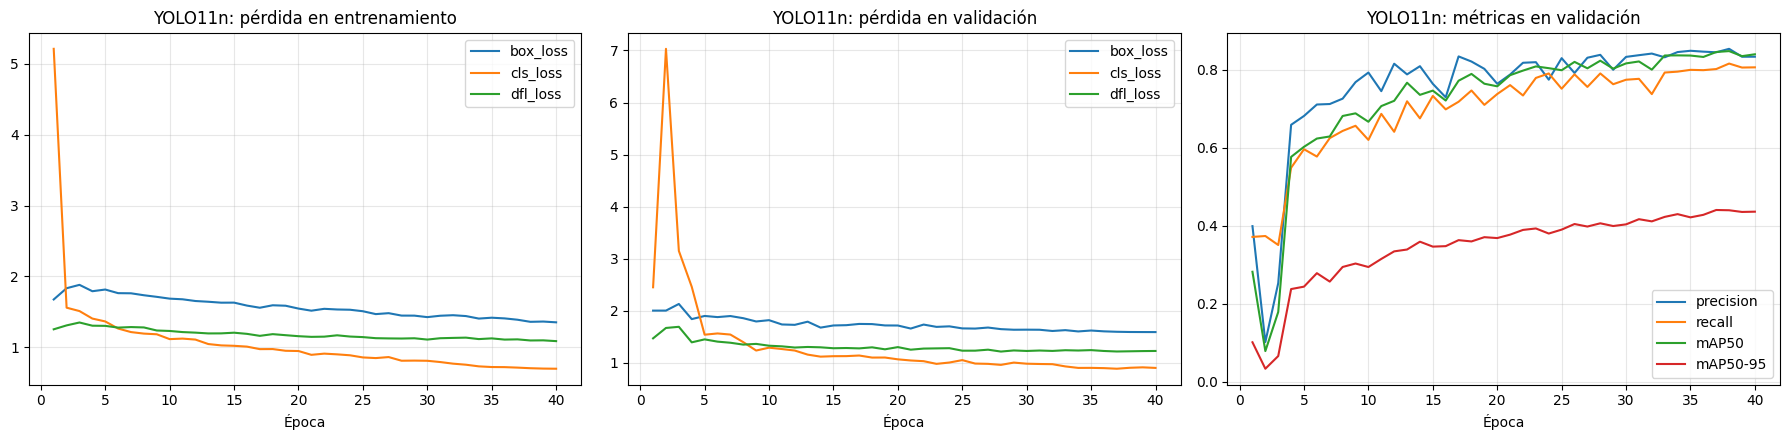

   modelo  epocas  mejor_epoca     P     R  mAP50  mAP50-95  tiempo_entrenamiento_min
  YOLO11n      40           37 0.845 0.802  0.845     0.440                      21.1
RT-DETR-L      40           38 0.827 0.855  0.854     0.466                      82.6


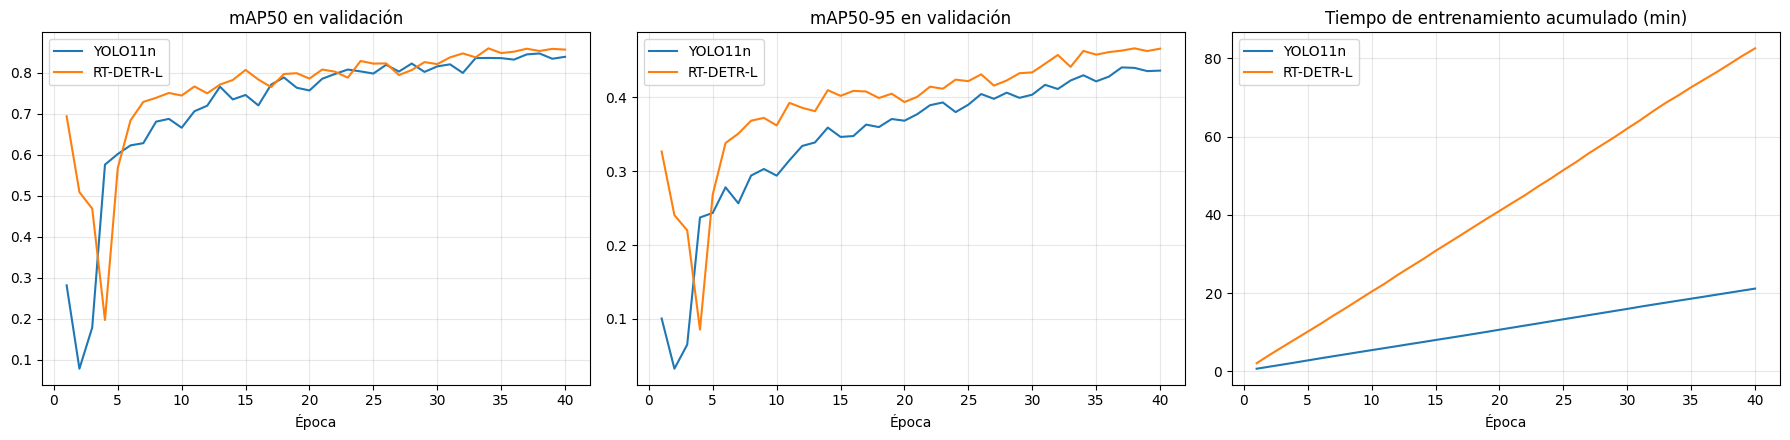

In [9]:
curvas = {}
for nombre, (_, run) in MODELOS.items():
    df = pd.read_csv(run / "results.csv")
    df.columns = df.columns.str.strip()
    curvas[nombre] = df

# pérdidas y métricas de YOLO11n
df = curvas["YOLO11n"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for p in ["box_loss", "cls_loss", "dfl_loss"]:
    axes[0].plot(df["epoch"], df["train/" + p], label=p)
    axes[1].plot(df["epoch"], df["val/" + p], label=p)
axes[0].set_title("YOLO11n: pérdida en entrenamiento"); axes[1].set_title("YOLO11n: pérdida en validación")
for m in ["precision", "recall", "mAP50", "mAP50-95"]:
    axes[2].plot(df["epoch"], df["metrics/" + m + "(B)"], label=m)
axes[2].set_title("YOLO11n: métricas en validación")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(BASE / "resultados" / "entrenamiento.png", dpi=120); plt.show()

filas_ent = []
for nombre, d in curvas.items():
    mejor = d.loc[d["metrics/mAP50-95(B)"].idxmax()]
    filas_ent.append({"modelo": nombre, "epocas": int(d["epoch"].max()), "mejor_epoca": int(mejor["epoch"]),
                      "P": round(mejor["metrics/precision(B)"], 3), "R": round(mejor["metrics/recall(B)"], 3),
                      "mAP50": round(mejor["metrics/mAP50(B)"], 3), "mAP50-95": round(mejor["metrics/mAP50-95(B)"], 3),
                      "tiempo_entrenamiento_min": round(d["time"].max() / 60, 1) if "time" in d.columns else None})
tabla_ent = pd.DataFrame(filas_ent)
print(tabla_ent.to_string(index=False))

if len(curvas) > 1:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for nombre, d in curvas.items():
        axes[0].plot(d["epoch"], d["metrics/mAP50(B)"], label=nombre)
        axes[1].plot(d["epoch"], d["metrics/mAP50-95(B)"], label=nombre)
        if "time" in d.columns:
            axes[2].plot(d["epoch"], d["time"] / 60, label=nombre)
    axes[0].set_title("mAP50 en validación"); axes[1].set_title("mAP50-95 en validación"); axes[2].set_title("Tiempo de entrenamiento acumulado (min)")
    for ax in axes:
        ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.savefig(BASE / "resultados" / "extra_curvas_yolo_rtdetr.png", dpi=120); plt.show()

## Extra: YOLO vs RT-DETR
**Mismas 300 imágenes de validación y mismo código de evaluación para los modelos.** Dos configuraciones: la estándar de Ultralytics (la que da el mAP)
y `conf=0,25` (punto de trabajo realista). Después se mide el coste (parámetros, GFLOPs, ms por imagen).

In [10]:
if necesita_dataset and len(MODELOS) > 0:
    filas = []
    for nombre in MODELOS:
        m = cargar(nombre)
        est = m.val(data=str(YAML), split="val", imgsz=IMGSZ, device=DEVICE, plots=False, verbose=False)
        c25 = m.val(data=str(YAML), split="val", imgsz=IMGSZ, conf=0.25, device=DEVICE, plots=False, verbose=False)
        filas.append({"modelo": nombre, "P": est.box.mp, "R": est.box.mr, "mAP50": est.box.map50, "mAP50-95": est.box.map,
                      "P@0.25": c25.box.mp, "R@0.25": c25.box.mr, "mAP50@0.25": c25.box.map50, "mAP50-95@0.25": c25.box.map})
    tabla_val = pd.DataFrame(filas).set_index("modelo").round(3)
    print(tabla_val.to_string())

    val_imgs = sorted((DATASET / "val" / "images").glob("*"))

    def medir_velocidad(m, imgs, n_calentamiento=10):
        for p in imgs[:n_calentamiento]:
            m.predict(str(p), imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)
        pre = inf = post = 0.0
        for p in imgs:
            v = m.predict(str(p), imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0].speed
            pre += v["preprocess"]; inf += v["inference"]; post += v["postprocess"]
        n = len(imgs)
        return pre / n, inf / n, post / n

    filas = []
    for nombre, (_, run) in MODELOS.items():
        m = cargar(nombre)
        pre, inf, post = medir_velocidad(m, val_imgs)
        params = sum(p.numel() for p in m.model.parameters()) / 1e6
        try:
            gflops = float(m.info(verbose=False)[3])
        except Exception:
            gflops = float("nan")
        filas.append({"modelo": nombre, "parametros_M": round(params, 1), "GFLOPs": round(gflops, 1),
                      "peso_best_pt_MB": round((run / "weights" / "best.pt").stat().st_size / 1e6, 1),
                      "inferencia_ms": round(inf, 1), "total_ms": round(pre + inf + post, 1), "img_por_s": round(1000 / (pre + inf + post), 1)})
    tabla_efi = pd.DataFrame(filas).set_index("modelo")
    print(tabla_efi.to_string())
else:
    tabla_val = tabla_efi = None
    print('Sin dataset -> se omiten la validación y la medida de velocidad.')

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2029.9±1057.2 MB/s, size: 376.8 KB)
val: Scanning /content/work/dataset/val/labels... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 1.8Kit/s 0.2s
val: New cache created: /content/work/dataset/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 5.5it/s 3.4s
                   all        300        434      0.845      0.805      0.847      0.439
Speed: 1.0ms preprocess, 3.5ms inference, 0.0ms loss, 2.1ms postprocess per image
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3903.1±821.2 MB/s, size: 375.4 KB)
val: S

### Las 30 fotos de matrículas españolas

modelo                                     YOLO11n                                                          RT-DETR-L
fotos_con_matricula                          29/30                                                              30/30
cajas_totales                                   32                                                                 36
fotos_sin_deteccion                  [coche13.jpg]                                                                 []
fotos_con_varias_cajas  [coche14.jpg, coche28.jpg]  [coche04.jpg, coche08.jpg, coche13.jpg, coche15.jpg, coche24.jpg]
conf_media                                    0.72                                                              0.865


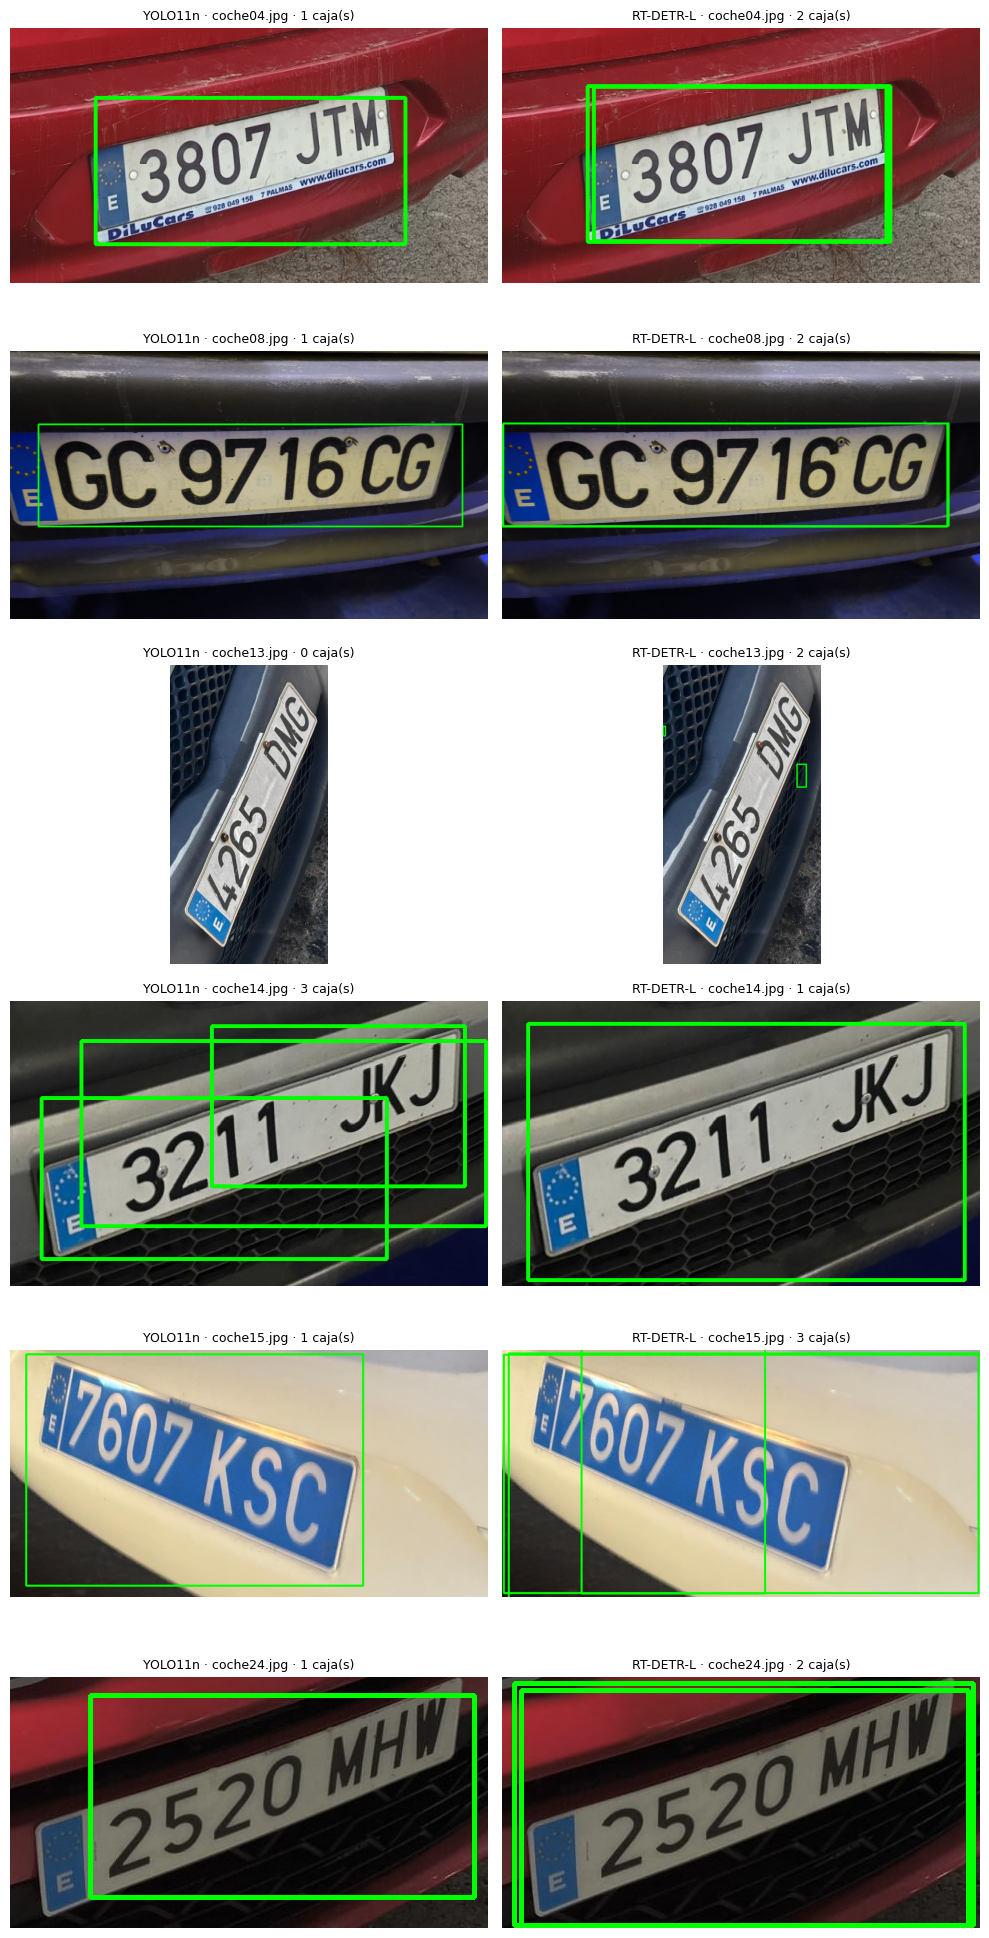

In [11]:
CONF_FOTOS = 0.25
fotos = sorted(p for p in DIR_PROPIAS.iterdir() if p.suffix.lower() in EXT)
det_fotos = {n: {} for n in MODELOS}
for nombre in MODELOS:
    m = cargar(nombre)
    for p in fotos:
        r = m.predict(str(p), imgsz=IMGSZ, conf=CONF_FOTOS, device=DEVICE, verbose=False)[0]
        det_fotos[nombre][p.name] = list(zip(r.boxes.xyxy.cpu().tolist(), r.boxes.conf.cpu().tolist()))

filas = []
for nombre, d in det_fotos.items():
    con = [k for k, v in d.items() if v]
    filas.append({"modelo": nombre, "fotos_con_matricula": f"{len(con)}/{len(fotos)}", "cajas_totales": sum(len(v) for v in d.values()),
                  "fotos_sin_deteccion": [k for k, v in d.items() if not v],
                  "fotos_con_varias_cajas": [k for k, v in d.items() if len(v) > 1],
                  "conf_media": round(float(np.mean([max(c for _, c in v) for v in d.values() if v])), 3)})
tabla_fotos = pd.DataFrame(filas).set_index("modelo")
print(tabla_fotos.T.to_string())

nombres = list(MODELOS)
dif = [p for p in fotos if len({len(det_fotos[n][p.name]) for n in nombres}) > 1]
elegidas = (dif + [p for p in fotos if p not in dif])[:6]
fig, axes = plt.subplots(len(elegidas), len(nombres), figsize=(5 * len(nombres), 3.3 * len(elegidas)))
axes = np.atleast_2d(axes).reshape(len(elegidas), len(nombres))
for i, p in enumerate(elegidas):
    for j, nombre in enumerate(nombres):
        im = cv2.imread(str(p))
        for (x1, y1, x2, y2), c in det_fotos[nombre][p.name]:
            cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), max(3, im.shape[1] // 300))
        axes[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[i, j].axis("off")
        axes[i, j].set_title(f"{nombre} · {p.name} · {len(det_fotos[nombre][p.name])} caja(s)", fontsize=9)
plt.tight_layout(); plt.savefig(BASE / "resultados" / "extra_fotos_yolo_rtdetr.png", dpi=100); plt.show()

### Recortes de vehículos del vídeo
Se extraen recortes de vehículos de unos 200 fotogramas repartidos por el vídeo y se aplica cada detector a **los mismos recortes**. Se mide la **tasa de detección** y el **solape** entre modelos.

310 recortes de vehículos de 2832 fotogramas (1 de cada 14)
           recortes  con_matricula  tasa_deteccion_%  conf_media  ms_por_recorte
modelo                                                                          
YOLO11n         310            115              37.1       0.602            11.8
RT-DETR-L       310            255              82.3       0.632            40.8
Solape: {'ambos': 114, 'solo YOLO11n': 1, 'solo RT-DETR-L': 141, 'ninguno': 54}


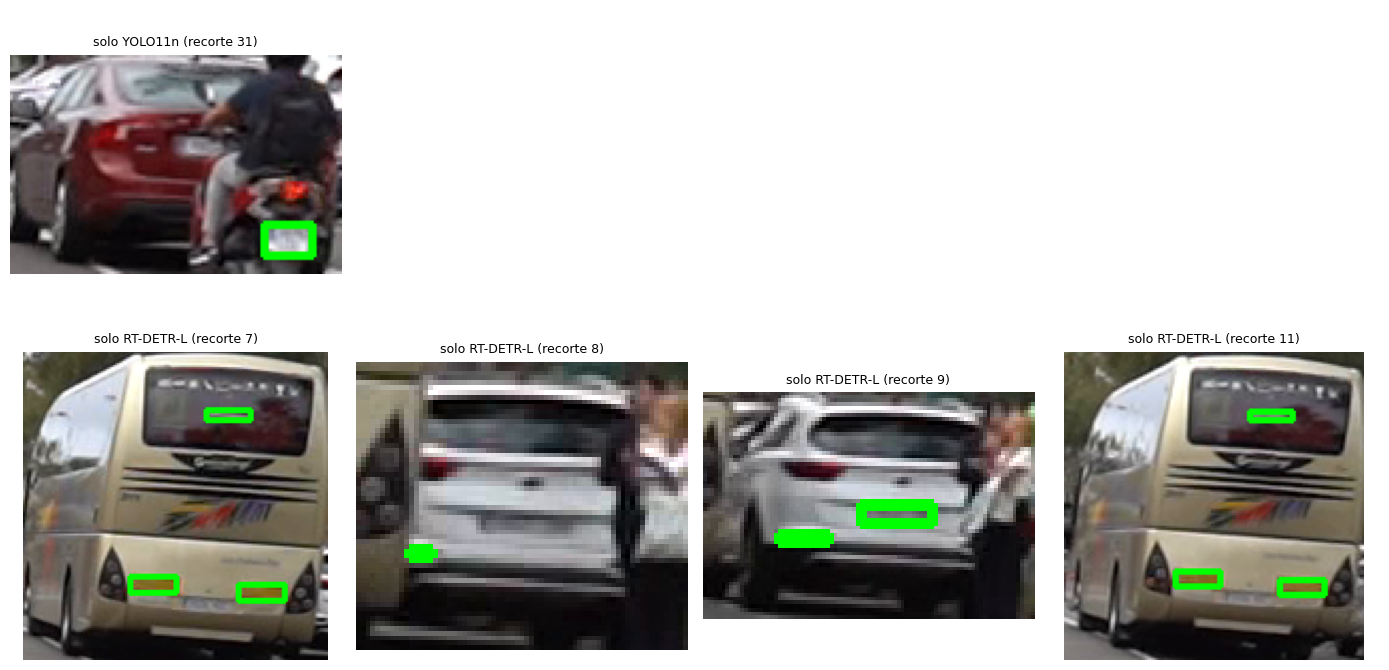

In [12]:
if len(MODELOS) > 1:
    VIDEO_LOCAL = WORK / VIDEO.name
    if not VIDEO_LOCAL.exists():
        shutil.copy2(VIDEO, VIDEO_LOCAL)

    det_general = YOLO(MODELO_GENERAL)
    cap = cv2.VideoCapture(str(VIDEO_LOCAL))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    paso = max(1, total // 200)
    recortes = []
    for idx in range(0, total, paso):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            continue
        r = det_general.predict(frame, classes=[2, 3, 5, 7], conf=CONF, device=DEVICE, verbose=False)[0]
        for x1, y1, x2, y2 in r.boxes.xyxy.cpu().tolist():
            if y2 - y1 >= ALTO_MIN_VEHICULO:
                recortes.append(frame[int(y1):int(y2), int(x1):int(x2)].copy())
    cap.release()
    recortes = recortes[:400]
    print(f"{len(recortes)} recortes de vehículos de {total} fotogramas (1 de cada {paso})")

    res_video = {}
    for nombre in MODELOS:
        m = cargar(nombre)
        for c in recortes[:10]:
            m.predict(c, imgsz=IMGSZ, conf=CONF_MAT, device=DEVICE, verbose=False)
        hay, confs, tiempos = [], [], []
        for c in recortes:
            r = m.predict(c, imgsz=IMGSZ, conf=CONF_MAT, device=DEVICE, verbose=False)[0]
            hay.append(len(r.boxes) > 0)
            confs.append(float(r.boxes.conf.max()) if len(r.boxes) else np.nan)
            tiempos.append(sum(r.speed.values()))
        res_video[nombre] = {"hay": np.array(hay), "conf": np.array(confs), "ms": np.array(tiempos)}

    tabla_video = pd.DataFrame([{"modelo": n, "recortes": len(recortes), "con_matricula": int(v["hay"].sum()),
                                 "tasa_deteccion_%": round(100 * v["hay"].mean(), 1),
                                 "conf_media": round(float(np.nanmean(v["conf"])), 3), "ms_por_recorte": round(float(v["ms"].mean()), 1)}
                                for n, v in res_video.items()]).set_index("modelo")
    print(tabla_video.to_string())

    A, B = "YOLO11n", "RT-DETR-L"
    ha, hb = res_video[A]["hay"], res_video[B]["hay"]
    solape = {"ambos": int((ha & hb).sum()), f"solo {A}": int((ha & ~hb).sum()), f"solo {B}": int((~ha & hb).sum()), "ninguno": int((~ha & ~hb).sum())}
    print("Solape:", solape)

    modelos_par = {A: cargar(A), B: cargar(B)}
    casos = [("solo " + A, np.where(ha & ~hb)[0][:4], A), ("solo " + B, np.where(~ha & hb)[0][:4], B)]
    filas_fig = sum(1 for _, idx, _ in casos if len(idx))
    if filas_fig:
        fig, axes = plt.subplots(filas_fig, 4, figsize=(14, 3.4 * filas_fig))
        axes = np.atleast_2d(axes)
        fi = 0
        for titulo, idx, quien in casos:
            if not len(idx):
                continue
            for j in range(4):
                axes[fi, j].axis("off")
            for j, k in enumerate(idx):
                im = recortes[k].copy()
                r = modelos_par[quien].predict(im, imgsz=IMGSZ, conf=CONF_MAT, device=DEVICE, verbose=False)[0]
                for x1, y1, x2, y2 in r.boxes.xyxy.cpu().tolist():
                    cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
                axes[fi, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[fi, j].set_title(f"{titulo} (recorte {k})", fontsize=9)
            fi += 1
        plt.tight_layout(); plt.savefig(BASE / "resultados" / "extra_video_desacuerdos.png", dpi=100); plt.show()
else:
    tabla_video = None
    print('Sólo hay un modelo -> no hay comparación sobre recortes del vídeo')

### Resumen de la comparativa y elección del detector de matrículas

           P@0.25  R@0.25  mAP50  mAP50-95  parametros_M  peso_best_pt_MB  total_ms  img_por_s  tiempo_entrenamiento_min  tasa_deteccion_%
modelo                                                                                                                                    
YOLO11n     0.845   0.806  0.847     0.439           2.6              5.5      14.2       70.3                      21.1              37.1
RT-DETR-L   0.828   0.855  0.854     0.466          32.8             66.2      40.3       24.8                      82.6              82.3


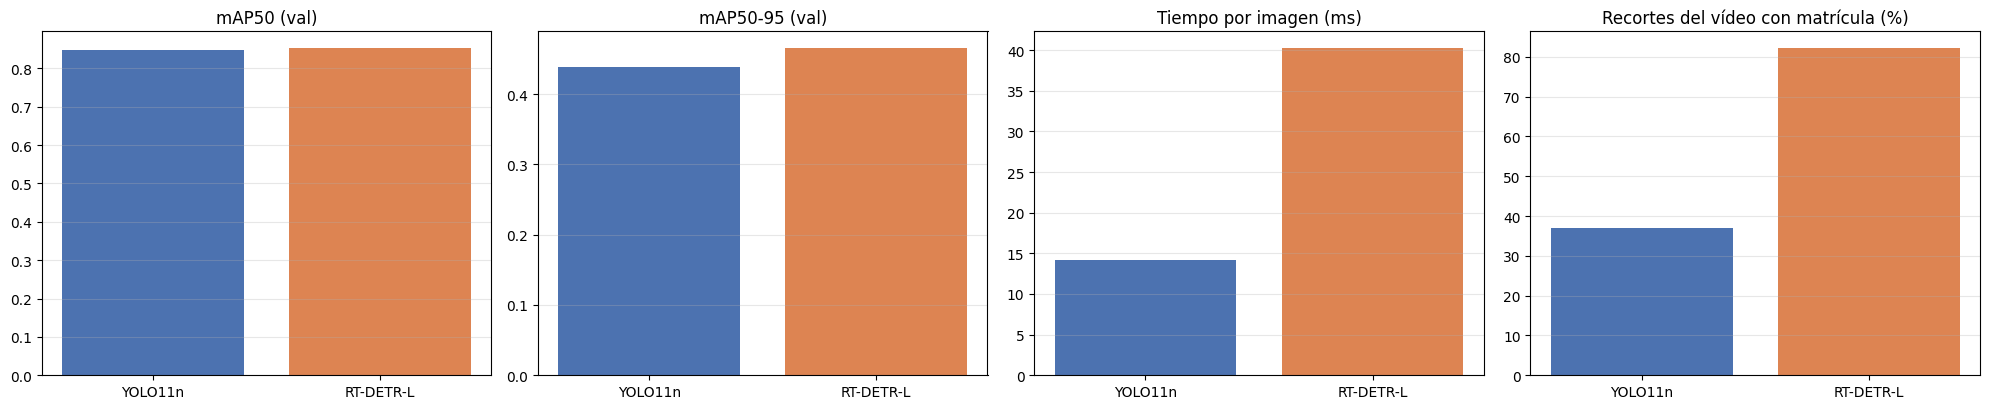


Tabla Markdown para el README
| Modelo | Precisión@0,25 | Recall@0,25 | mAP50 | mAP50-95 | Parámetros (M) | ms/imagen | Entrenamiento (min) | Detección en vídeo (%) |
|---|---|---|---|---|---|---|---|---|
| YOLO11n | 0.845 | 0.806 | 0.847 | 0.439 | 2.6 | 14.2 | 21.1 | 37.1 |
| RT-DETR-L | 0.828 | 0.855 | 0.854 | 0.466 | 32.8 | 40.3 | 82.6 | 82.3 |


Detector de matrículas usado en el vídeo: RT-DETR-L


In [13]:
if len(MODELOS) > 1 and tabla_val is not None:
    resumen = pd.concat([tabla_val[["P@0.25", "R@0.25", "mAP50", "mAP50-95"]],
                         tabla_efi[["parametros_M", "peso_best_pt_MB", "total_ms", "img_por_s"]],
                         tabla_ent.set_index("modelo")[["tiempo_entrenamiento_min"]],
                         tabla_video[["tasa_deteccion_%"]]], axis=1)
    resumen.to_csv(BASE / "resultados" / "comparativa_detectores.csv")
    print(resumen.to_string())
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    cols = ["#4c72b0", "#dd8452", "#55a868"][:len(resumen)]
    for ax, (col, tit) in zip(axes, [("mAP50", "mAP50 (val)"), ("mAP50-95", "mAP50-95 (val)"),
                                     ("total_ms", "Tiempo por imagen (ms)"), ("tasa_deteccion_%", "Recortes del vídeo con matrícula (%)")]):
        ax.bar(resumen.index, resumen[col], color=cols); ax.set_title(tit); ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.savefig(BASE / "resultados" / "comparativa_detectores.png", dpi=120); plt.show()

    md_tabla = "| Modelo | Precisión@0,25 | Recall@0,25 | mAP50 | mAP50-95 | Parámetros (M) | ms/imagen | Entrenamiento (min) | Detección en vídeo (%) |\n|---|---|---|---|---|---|---|---|---|\n"
    for n, f in resumen.iterrows():
        md_tabla += (f"| {n} | {f['P@0.25']:.3f} | {f['R@0.25']:.3f} | {f['mAP50']:.3f} | {f['mAP50-95']:.3f} | "
                     f"{f['parametros_M']} | {f['total_ms']} | {f['tiempo_entrenamiento_min']} | {f['tasa_deteccion_%']} |\n")
    print("\nTabla Markdown para el README\n" + md_tabla)

if DETECTOR_MATRICULAS == "auto":
    if tabla_val is not None:
        ELEGIDO = tabla_val["mAP50-95"].idxmax()
    else:
        ELEGIDO = tabla_ent.set_index("modelo")["mAP50-95"].idxmax()
else:
    ELEGIDO = DETECTOR_MATRICULAS
assert ELEGIDO in MODELOS, f"{ELEGIDO} no está entre {list(MODELOS)}"
print("\nDetector de matrículas usado en el vídeo:", ELEGIDO)
plate_model = cargar(ELEGIDO)

## OCR: recortes de matrículas, texto real y comparativa
Para medir el acierto hace falta el **texto verdadero** de cada matrícula.
Se corrigen tres cosas que falseaban la comparativa:
`coche14_0` y `coche28_0` son recortes **parciales** (no se ven todas las cifras o letras) y se excluyen; `coche28_1` es el recorte completo de esa matrícula y se incluye.

Recortes generados: 32


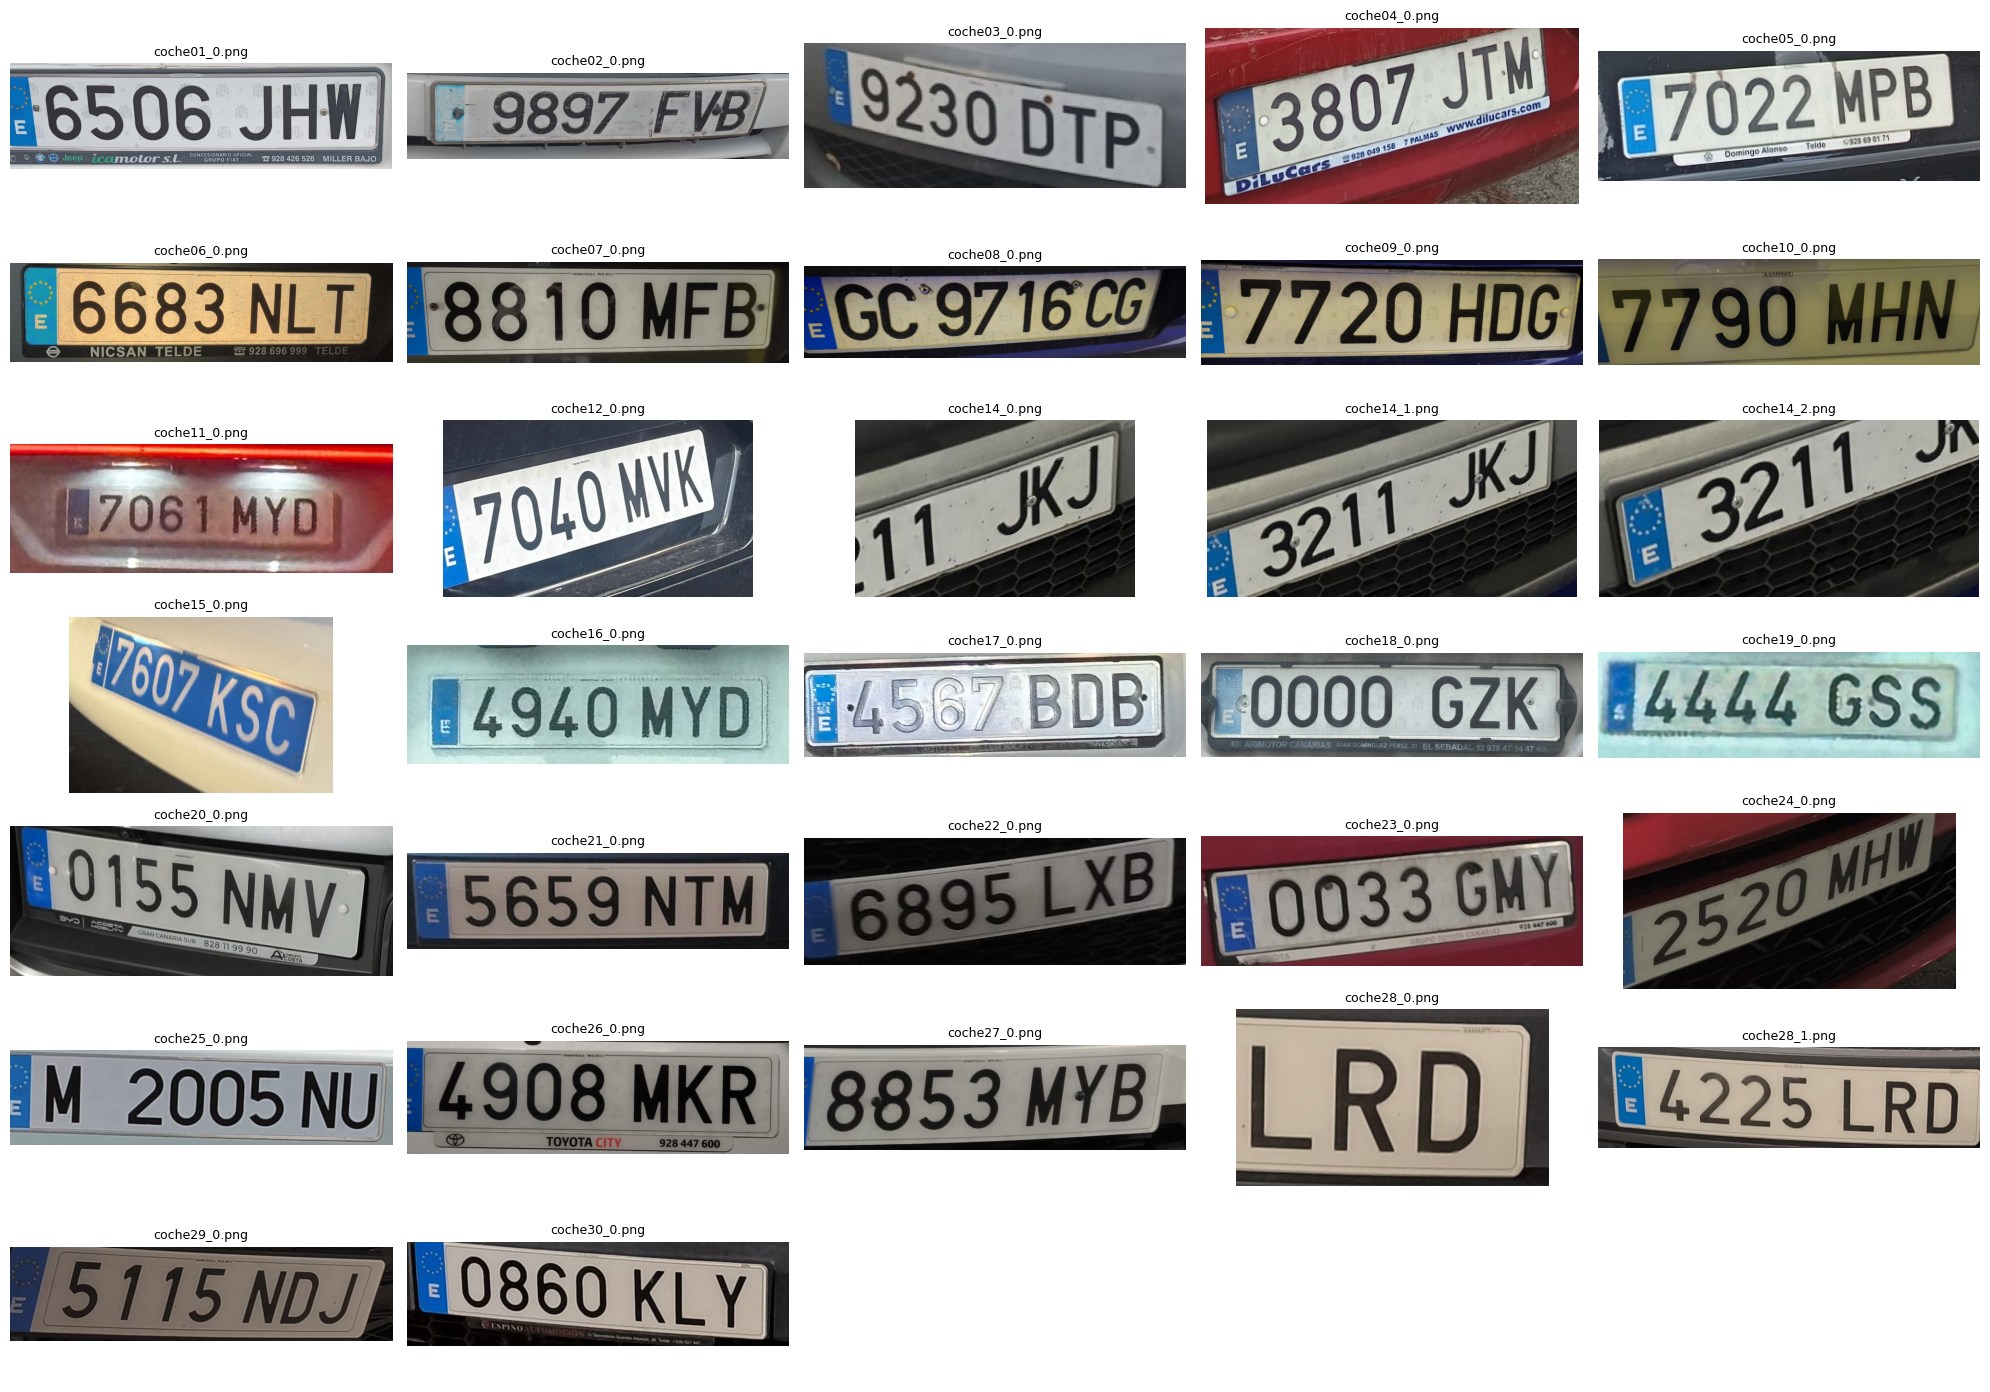

In [14]:
OCR_DIR = BASE / "ocr_dataset"
CSV_TEXTO = OCR_DIR / "matriculas_texto.csv"
MARGEN_RECORTE = 0.10
(OCR_DIR / "crops").mkdir(parents=True, exist_ok=True)

det_ocr = cargar(DETECTOR_RECORTES_OCR if DETECTOR_RECORTES_OCR in MODELOS else "YOLO11n")
n_crops = 0
for p in sorted(f for f in DIR_PROPIAS.iterdir() if f.suffix.lower() in EXT):
    im = cv2.imread(str(p))
    H, W = im.shape[:2]
    r = det_ocr.predict(im, imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
    for k, (x1, y1, x2, y2) in enumerate(r.boxes.xyxy.cpu().tolist()):
        w, h = (x2 - x1) * (1 + MARGEN_RECORTE), (y2 - y1) * (1 + MARGEN_RECORTE)
        xc, yc = (x1 + x2) / 2, (y1 + y2) / 2
        a, b, c, d = max(int(xc - w / 2), 0), max(int(yc - h / 2), 0), min(int(xc + w / 2), W), min(int(yc + h / 2), H)
        if c > a and d > b:
            cv2.imwrite(str(OCR_DIR / "crops" / f"{p.stem}_{k}.png"), im[b:d, a:c])
            n_crops += 1
print("Recortes generados:", n_crops)

crops = sorted((OCR_DIR / "crops").glob("*.png"))
columnas = 5
filas_fig = -(-len(crops) // columnas)
fig, axes = plt.subplots(filas_fig, columnas, figsize=(4 * columnas, 2 * filas_fig))
axes = np.atleast_1d(axes).ravel()
for ax in axes:
    ax.axis("off")
for ax, p in zip(axes, crops):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); ax.set_title(p.name, fontsize=9)
plt.tight_layout(); plt.savefig(BASE / "resultados" / "recortes_ocr.png", dpi=100); plt.show()

In [15]:
# texto real de cada recorte -> se excluye recorte parcial, ilegible o que no es una matrícula
textos = {
    "coche01_0.png": "6506JHW", "coche02_0.png": "9897FVB", "coche03_0.png": "9230DTP", "coche04_0.png": "3807JTM",
    "coche05_0.png": "7022MPB", "coche06_0.png": "6683NLT", "coche07_0.png": "8810MFB", "coche08_0.png": "GC9716CG",
    "coche09_0.png": "7720HDG", "coche10_0.png": "7790MHN", "coche11_0.png": "7061MYD", "coche12_0.png": "7040MVK",
    "coche14_0.png": "", # recorte parcial: sólo se ven "211 JKJ"
    "coche14_1.png": "3211JKJ",
    "coche14_2.png": "", # recorte parcial: la última letra queda cortada
    "coche15_0.png": "7607KSC", "coche16_0.png": "4940MYD", "coche17_0.png": "4567BDB", "coche18_0.png": "0000GZK",
    "coche19_0.png": "4444GSS", "coche20_0.png": "0155NMV", "coche21_0.png": "5659NTM", "coche22_0.png": "6895LXB",
    "coche23_0.png": "0033GMY", "coche24_0.png": "2520MHW", "coche25_0.png": "M2005NU", "coche26_0.png": "4908MKR",
    "coche27_0.png": "8853MYB",
    "coche28_0.png": "", # recorte parcial: sólo se ven las letras "LRD"
    "coche28_1.png": "4225LRD",
    "coche29_0.png": "5115NDJ", "coche30_0.png": "0860KLY",
}
df_txt = pd.DataFrame([{"recorte": k, "texto_real": re.sub(r"[^A-Z0-9]", "", v.upper())} for k, v in textos.items() if v.strip()])
df_txt.to_csv(CSV_TEXTO, index=False)
sin_etiqueta = [p.name for p in crops if p.name not in textos]
print("Recortes con texto real:", len(df_txt), "| recortes sin entrada en el diccionario:", sin_etiqueta)

Recortes con texto real: 29 | recortes sin entrada en el diccionario: []


### Motores de OCR

In [16]:
ALFABETO = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
VLM_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"
PROMPT_VLM = "Read the license plate in the image. Answer only with the plate characters, no spaces and no other text."

def normalizar(t):
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

def levenshtein(a, b):
    if a == b:
        return 0
    if not a or not b:
        return max(len(a), len(b))
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def sync():
    if USA_GPU:
        torch.cuda.synchronize()

def cargar_easyocr():
    import easyocr
    lector = easyocr.Reader(["es", "en"], gpu=USA_GPU, verbose=False)

    def leer(img_bgr):
        return "".join(lector.readtext(img_bgr, detail=0, allowlist=ALFABETO))
    return leer

def cargar_smolvlm():
    from PIL import Image
    from transformers import AutoProcessor
    try:
        from transformers import AutoModelForImageTextToText as AutoVLM
    except ImportError:
        from transformers import AutoModelForVision2Seq as AutoVLM
    dtype = torch.float16 if USA_GPU else torch.float32 # si sale texto raro con fp16, prueba torch.float32
    procesador = AutoProcessor.from_pretrained(VLM_ID)
    modelo_vlm = AutoVLM.from_pretrained(VLM_ID, torch_dtype=dtype).to("cuda" if USA_GPU else "cpu").eval()
    mensajes = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT_VLM}]}]
    prompt = procesador.apply_chat_template(mensajes, add_generation_prompt=True)

    def leer(img_bgr):
        pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        entrada = procesador(text=prompt, images=[pil], return_tensors="pt").to(modelo_vlm.device, dtype)
        with torch.no_grad():
            salida = modelo_vlm.generate(**entrada, max_new_tokens=16, do_sample=False)
        return procesador.batch_decode(salida, skip_special_tokens=True)[0].split("Assistant:")[-1]
    return leer

CARGADORES = {"easyocr": cargar_easyocr, "smolvlm": cargar_smolvlm}
_MOTORES = {}

def motor(nombre):
    if nombre not in _MOTORES:
        _MOTORES[nombre] = CARGADORES[nombre]()
    return _MOTORES[nombre]

In [17]:
def cargar_easyocr_filtrado():
    """EasyOCR quedándose sólo con los caracteres grandes (altura ≥ 60 % de la mayor): descarta rótulos y pegatinas."""
    import easyocr
    lector = easyocr.Reader(["es", "en"], gpu=USA_GPU, verbose=False)

    def leer(img_bgr):
        res = lector.readtext(img_bgr, detail=1, allowlist=ALFABETO)
        if not res:
            return ""
        alto = lambda b: max(p[1] for p in b) - min(p[1] for p in b)
        amax = max(alto(r[0]) for r in res)
        grandes = sorted([r for r in res if alto(r[0]) >= 0.6 * amax], key=lambda r: min(p[0] for p in r[0]))
        return "".join(r[1] for r in grandes)
    return leer

CARGADORES["easyocr_filtrado"] = cargar_easyocr_filtrado

### Comparativa de OCR (recortes limpios)
**Mismas condiciones:** mismos recortes, misma máquina, un recorte cada vez, 3 de calentamiento no contados y mismo normalizado.

**Métricas:** acierto exacto, CER y tiempo.

In [18]:
N_CALENTAMIENTO = 3

gt = pd.read_csv(CSV_TEXTO, dtype=str).fillna("")
gt = gt[gt["texto_real"] != ""].reset_index(drop=True)
print("Recortes con texto real:", len(gt), "(se recomienda ≥ 30)")

imagenes = [cv2.imread(str(OCR_DIR / "crops" / r)) for r in gt["recorte"]]
filas = []
for nombre in OCR_COMPARAR:
    leer = motor(nombre)
    for im in imagenes[:N_CALENTAMIENTO]: # calentamiento -> no se mide
        leer(im)
    for rec, real, im in zip(gt["recorte"], gt["texto_real"], imagenes):
        sync(); t0 = time.perf_counter()
        bruto = leer(im)
        sync(); dt = time.perf_counter() - t0
        pred = normalizar(bruto)
        filas.append({"motor": nombre, "recorte": rec, "texto_real": real, "texto_pred": pred,
                      "acierto": int(pred == real), "cer": levenshtein(real, pred) / max(len(real), 1),
                      "tiempo_s": dt})

comp = pd.DataFrame(filas)
comp.to_csv(BASE / "resultados" / "comparativa_ocr.csv", index=False)

resumen = comp.groupby("motor").agg(
    n=("acierto", "size"),
    acierto_pct=("acierto", lambda s: 100 * s.mean()),
    cer_medio=("cer", "mean"),
    tiempo_medio_ms=("tiempo_s", lambda s: 1000 * s.mean()),
    tiempo_mediano_ms=("tiempo_s", lambda s: 1000 * s.median()),
    tiempo_p95_ms=("tiempo_s", lambda s: 1000 * s.quantile(0.95)),
).round(2)
resumen["img_por_s"] = (1000 / resumen["tiempo_medio_ms"].clip(lower=1e-6)).round(2)
resumen.to_csv(BASE / "resultados" / "resumen_ocr.csv")
print(resumen.to_string())

Recortes con texto real: 29 (se recomienda ≥ 30)


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.3k [00:00<?, ?B/s]

... (7 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

                   n  acierto_pct  cer_medio  tiempo_medio_ms  tiempo_mediano_ms  tiempo_p95_ms  img_por_s
motor                                                                                                     
easyocr           29        27.59       1.51           105.01              81.05         232.84       9.52
easyocr_filtrado  29        79.31       0.03           125.08              95.00         264.05       7.99
smolvlm           29        79.31       0.11           590.59             586.46         851.41       1.69


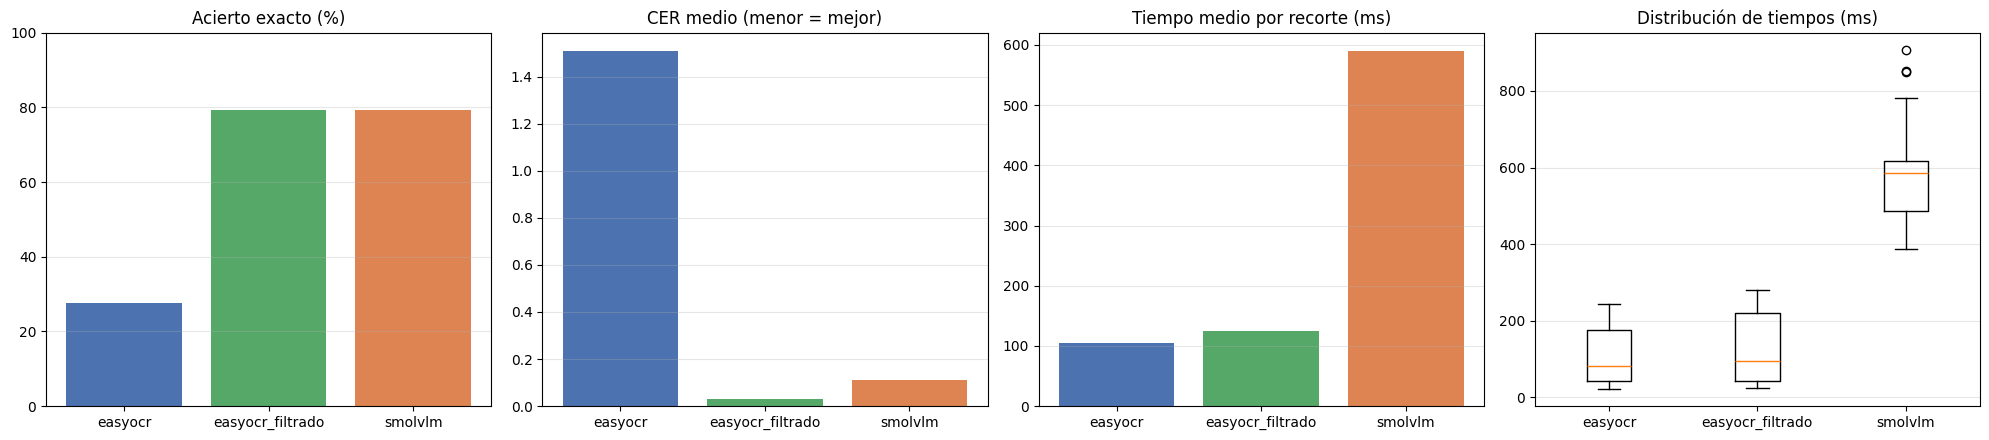


Peores lecturas de easyocr
      recorte texto_real                                                       texto_pred      cer
coche01_0.png    6506JHW E6506JHWCONCESIONARIOUFICIALJEPR0SLGRUPOFIAT0928426526MILLERBAJO 8.142857
coche18_0.png    0000GZK  E0000GZKARIMOTORCANARIASJUANDOMINGUEZPEREZ21ELSEBADAL0928471447 8.000000
coche20_0.png    0155NMV                         EGRANSUR8287199900155NMV942C5SECANAAIAQ6 4.714286
coche04_0.png    3807JTM                                 JTM3807COMWWIDIUA6SAPALMA282DIGS 3.857143
coche06_0.png    6683NLT                                E6683NLTNICSANTELDE928696999TELDE 3.714286

Peores lecturas de easyocr_filtrado
      recorte texto_real texto_pred      cer
coche05_0.png    7022MPB   7022MMPB 0.142857
coche12_0.png    7040MVK    7040KVK 0.142857
coche14_1.png    3211JKJ     3211JJ 0.142857
coche15_0.png    7607KSC   17607KSC 0.142857
coche24_0.png    2520MHW    2520MHV 0.142857

Peores lecturas de smolvlm
      recorte texto_real texto_pred      ce

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
motores = list(resumen.index)
axes[0].bar(motores, resumen["acierto_pct"], color=["#4c72b0", "#55a868", "#dd8452"][:len(motores)])
axes[0].set_title("Acierto exacto (%)"); axes[0].set_ylim(0, 100)
axes[1].bar(motores, resumen["cer_medio"], color=["#4c72b0", "#55a868", "#dd8452"][:len(motores)])
axes[1].set_title("CER medio (menor = mejor)")
axes[2].bar(motores, resumen["tiempo_medio_ms"], color=["#4c72b0", "#55a868", "#dd8452"][:len(motores)])
axes[2].set_title("Tiempo medio por recorte (ms)")
axes[3].boxplot([1000 * comp.loc[comp["motor"] == m, "tiempo_s"] for m in motores])
axes[3].set_xticks(range(1, len(motores) + 1))
axes[3].set_xticklabels(motores)
axes[3].set_title("Distribución de tiempos (ms)")
for ax in axes:
    ax.grid(alpha=.3, axis="y")
plt.tight_layout()
plt.savefig(BASE / "resultados" / "comparativa_ocr.png", dpi=120)
plt.show()

# errores más claros de cada motor
for m in motores:
    e = comp[(comp["motor"] == m) & (comp["acierto"] == 0)].sort_values("cer", ascending=False).head(5)
    print(f"\nPeores lecturas de {m}")
    print(e[["recorte", "texto_real", "texto_pred", "cer"]].to_string(index=False))

## Prototipo sobre el vídeo

1. **Seguimiento** de personas y vehículos (YOLO11n + tracker de Ultralytics).
2. **Matrícula** buscada en el recorte de cada vehículo (con margen), con el detector elegido; se guardan los `K_RECORTES` mejores por vehículo (confianza * tamaño * nitidez).
3. **Conteo:** sólo cuentan los tracks que duran un mínimo de fotogramas, **no son demasiado pequeños** (los objetos lejanos se fragmentan en muchos identificadores y inflan el recuento) y **se mueven**: es decir, su dirección no es "parado" (un coche que se acerca o se aleja apenas se mueve de lado, así que primero se mira el cambio de tamaño de la caja).
4. **Lectura por votación:** cada recorte se lee con varios OCR; sólo se aceptan lecturas con formato de matrícula española y se exigen `MIN_VOTOS` coincidencias.
5. **Flujo con corrección de perspectiva:** la cámara está en medio de la carretera, así que lo normal es que los vehículos *se acerquen* o *se alejen*. Usa **exactamente el mismo criterio** que el conteo: primero el cambio de tamaño de la caja y, sólo si casi no cambia, el desplazamiento lateral.
6. Salidas: `resultado.csv`, `resultado.mp4`, `resultado_anonimizado.mp4` (extra) y `resultados/resumen_video.json`.

In [20]:
VIDEO_LOCAL = WORK / VIDEO.name
if not VIDEO_LOCAL.exists():
    shutil.copy2(VIDEO, VIDEO_LOCAL)

detector = YOLO(MODELO_GENERAL)
cap = cv2.VideoCapture(str(VIDEO_LOCAL))
FPS = cap.get(cv2.CAP_PROP_FPS)
ANCHO = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
print(f"Vídeo: {ANCHO}x{ALTO}, {FPS:.1f} fps, {N_TOTAL} fotogramas -> se procesa 1 de cada {SALTO}")

TRACKER_ARG = TRACKER
if TRACKER_OVERRIDES:
    try:
        from ultralytics.cfg import ROOT as ULTRALYTICS_ROOT
        from ultralytics.utils import YAML as UYAML
        cfg = UYAML.load(ULTRALYTICS_ROOT / "cfg" / "trackers" / TRACKER)
        cfg.update(TRACKER_OVERRIDES)
        UYAML.save(WORK / "tracker_custom.yaml", cfg)
        TRACKER_ARG = str(WORK / "tracker_custom.yaml")
    except Exception as e:
        print("Aviso: no se pudo personalizar el tracker, se usa el de por defecto:", e)

detecciones = []
mejores = defaultdict(list) # id -> [(puntuación, recorte de matrícula)]

cap = cv2.VideoCapture(str(VIDEO_LOCAL))
t0 = time.perf_counter()
n_frame, idx = -1, -1
while True:
    ok, frame = cap.read()
    if not ok:
        break
    idx += 1
    if idx % SALTO != 0:
        continue
    if LIMITE and n_frame + 1 >= LIMITE:
        break
    n_frame += 1
    if n_frame % 100 == 0:
        print(f"  procesados {n_frame} fotogramas ({time.perf_counter() - t0:.0f} s)", flush=True)
    r = detector.track(frame, persist=True, verbose=False, classes=list(CLASES), conf=CONF, device=DEVICE, tracker=TRACKER_ARG)[0]
    if r.boxes.id is None:
        continue
    ids = r.boxes.id.int().cpu().tolist()
    clases = r.boxes.cls.int().cpu().tolist()
    confs = r.boxes.conf.cpu().tolist()
    cajas = r.boxes.xyxy.cpu().tolist()

    for tid, cid, conf, caja in zip(ids, clases, confs, cajas):
        x1, y1, x2, y2 = [int(v) for v in caja]
        x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, ANCHO), min(y2, ALTO)
        fila = {"fotograma": n_frame, "tipo": cid, "confianza": round(conf, 3), "id": tid,
                "x1": x1, "y1": y1, "x2": x2, "y2": y2, "mat": None}

        if cid in VEHICULOS and cid != 1 and (y2 - y1) >= ALTO_MIN_VEHICULO:
            mx, my = int(MARGEN_VEH * (x2 - x1)), int(MARGEN_VEH * (y2 - y1))
            rx1, ry1, rx2, ry2 = max(0, x1 - mx), max(0, y1 - my), min(ANCHO, x2 + mx), min(ALTO, y2 + my)
            rm = plate_model.predict(frame[ry1:ry2, rx1:rx2], imgsz=IMGSZ, conf=CONF_MAT, device=DEVICE, verbose=False)[0]
            if len(rm.boxes) > 0:
                k = int(rm.boxes.conf.argmax())
                p, q, s, t = [int(v) for v in rm.boxes.xyxy[k].tolist()]
                cm = round(float(rm.boxes.conf[k]), 3)
                a, b, c, d = p + rx1, q + ry1, s + rx1, t + ry1 # recorte del vehículo -> fotograma
                fila["mat"] = (cm, a, b, c, d)
                rec = frame[b:d, a:c]
                if rec.size:
                    nitidez = cv2.Laplacian(cv2.cvtColor(rec, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()
                    puntuacion = cm * np.sqrt(rec.shape[0] * rec.shape[1]) * np.log1p(nitidez)
                    mejores[tid].append((puntuacion, rec.copy()))
                    mejores[tid].sort(key=lambda z: -z[0])
                    del mejores[tid][K_RECORTES:]
        detecciones.append(fila)
cap.release()
T_PASADA = time.perf_counter() - t0
tramos = defaultdict(list)
for d in detecciones:
    tramos[d["id"]].append(d)
print(f"Fotogramas leídos: {idx + 1} | procesados: {n_frame + 1} | {T_PASADA:.0f} s ({(n_frame + 1) / T_PASADA:.1f} fotogramas/s) | identificadores sin filtrar: {len(tramos)}")

Vídeo: 1920x1080, 25.0 fps, 2832 fotogramas -> se procesa 1 de cada 1
  procesados 0 fotogramas (0 s)
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 281ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

  procesados 100 fotogramas (9 s)
  procesados 200 fotogramas (21 s)
  procesados 300 fotogramas (28 s)
  procesados 400 fotogramas (32 s)
  procesados 500 fotogramas (41 s)
  procesados 600 fotogramas (45 s)
  procesados 700 fotogramas (53 s)
  procesados 800 fotogramas (62 s)
  procesados 900 fotogramas (71 s)
  procesados 1000 fotogramas (78 s)
  procesados 1100 fotogramas (89 s)
  procesados 1200 fotogramas (93 s)
  procesados 1300 fotogramas (104 s)
  procesados 1400 fotogramas (116 s)
  procesados 1500 fotogramas (131 s)
  proces

In [21]:
def clase_mayoritaria(tramo):
    return Counter(d["tipo"] for d in tramo).most_common(1)[0][0]

def alto_med(L):
    return np.mean([d["y2"] - d["y1"] for d in L])

def centro(L):
    return np.array([np.mean([(d["x1"] + d["x2"]) / 2 for d in L]), np.mean([(d["y1"] + d["y2"]) / 2 for d in L])])

def cambio_escala(tramo):
    return alto_med(tramo[-5:]) / max(alto_med(tramo[:5]), 1)

def direccion(tramo):
    """Dirección del movimiento del track"""
    esc = cambio_escala(tramo)
    if esc >= ESCALA_CAMBIO:
        return "se acerca"
    if esc <= 1 / ESCALA_CAMBIO:
        return "se aleja"
    desp = centro(tramo[-5:]) - centro(tramo[:5])
    minimo = MIN_MOV_PERSONA if clase_mayoritaria(tramo) == CLASE_PERSONA else MIN_MOV_VEHICULO
    if np.linalg.norm(desp) < minimo * ANCHO:
        return "parado"
    return "derecha" if desp[0] > 0 else "izquierda"

def se_cuenta(tramo):
    if len(tramo) < MIN_FRAMES:
        return False
    if max(d["y2"] - d["y1"] for d in tramo) < MIN_ALTO_REL * ALTO:
        return False
    return direccion(tramo) != "parado" # un objeto que no se mueve (p. ej. aparcado) no cuenta

clase_track = {t: clase_mayoritaria(L) for t, L in tramos.items()}
contados = {t for t, L in tramos.items() if se_cuenta(L)}
conteo = Counter(CLASES[clase_track[t]] for t in contados)
print("Total PERSONAS :", conteo["persona"])
print("Total VEHÍCULOS:", sum(v for k, v in conteo.items() if k != "persona"))
print("Por clase      :", dict(conteo))
print(f"(de {len(tramos)} identificadores, {len(contados)} cumplen las condiciones)")

Total PERSONAS : 15
Total VEHÍCULOS: 37
Por clase      : {'persona': 15, 'autobus': 1, 'coche': 33, 'moto': 2, 'bicicleta': 1}
(de 268 identificadores, 52 cumplen las condiciones)


Vehículos contados: 36 | con matrícula detectada: 32 | con texto válido: 2
Ancho de los recortes de matrícula en el vídeo (px): mín 6 · mediana 81 · máx 233


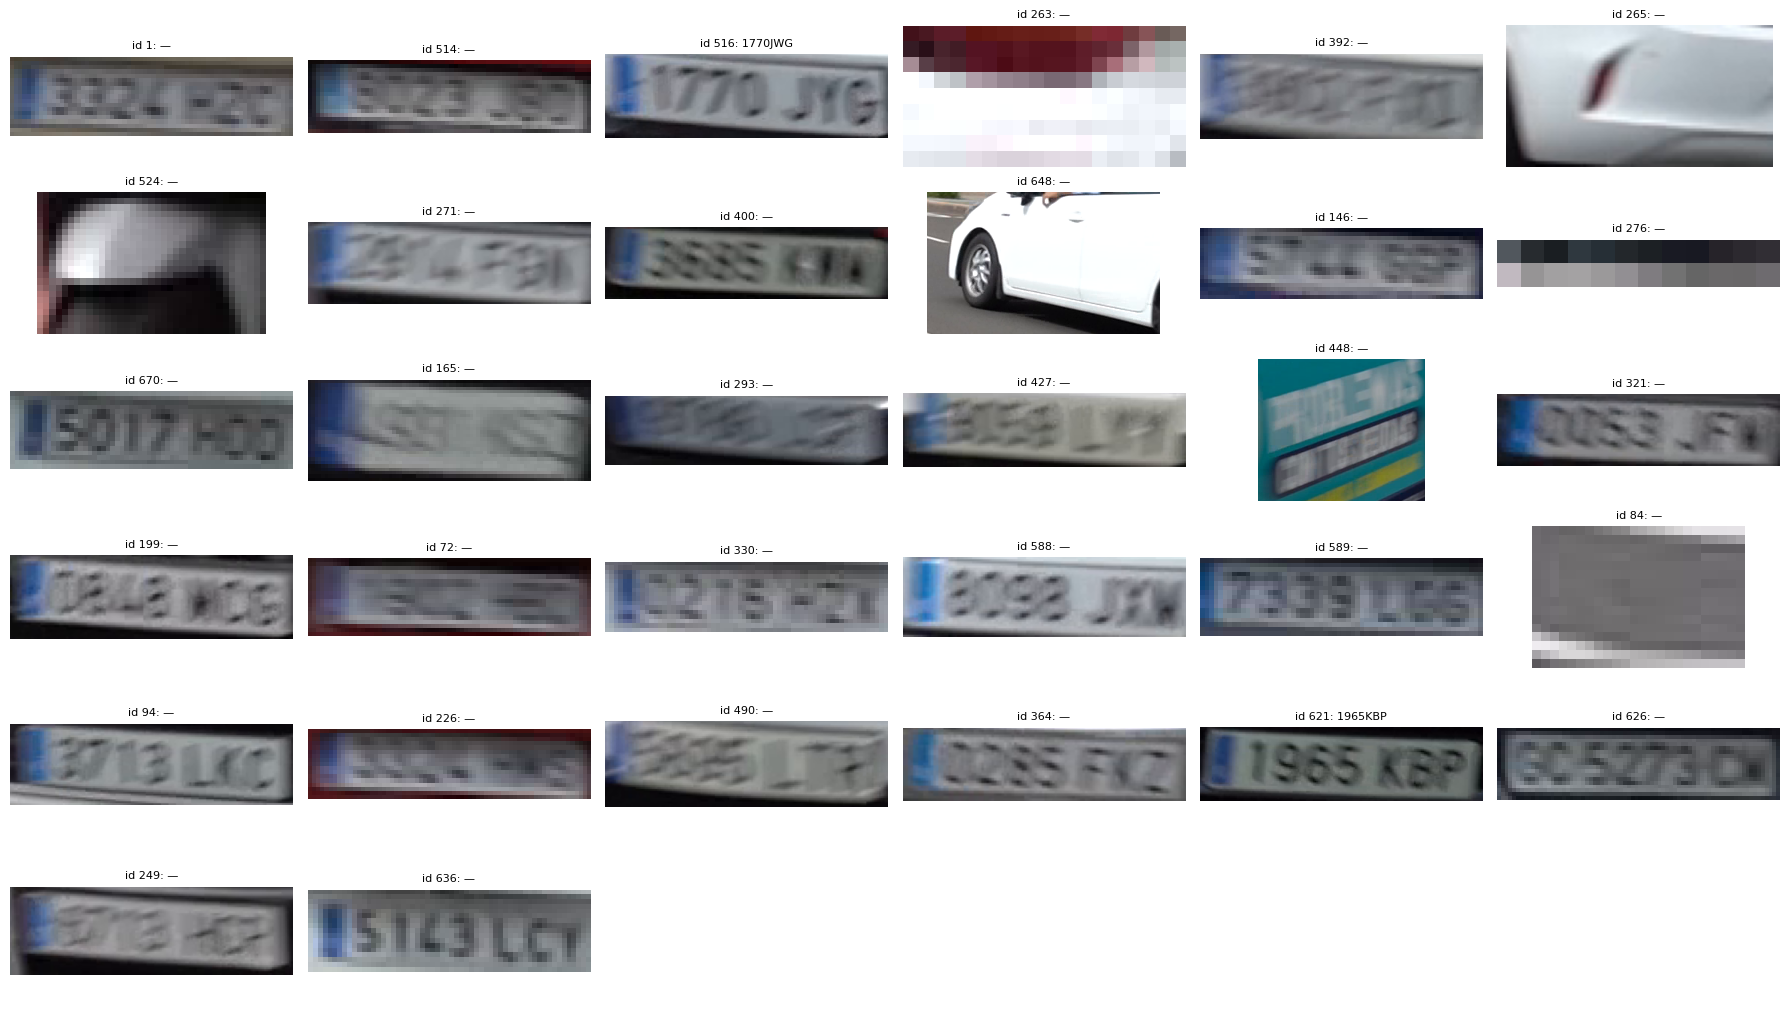

In [22]:
# lectura de matrículas por votación (varios recortes * varios OCR)
PATRON_NUEVO = re.compile(r"^\d{4}[BCDFGHJKLMNPRSTVWXYZ]{3}$") # 1234ABC
PATRON_ANTIGUO = re.compile(r"^[A-Z]{1,2}\d{4}[A-Z]{1,2}$") # GC1234CG
A_NUM = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "G": "6", "T": "7", "B": "8"}
A_LET = {"0": "D", "1": "L", "2": "Z", "5": "S", "6": "G", "8": "B"}

def corregir_es(t):
    """Sólo corrige confusiones (O/0, I/1...) si el resultado tiene el formato nuevo 1234ABC."""
    if len(t) != 7:
        return t
    c = "".join(A_NUM.get(x, x) for x in t[:4]) + "".join(A_LET.get(x, x) for x in t[4:])
    return c if PATRON_NUEVO.match(c) else t

def es_valida(t):
    return bool(PATRON_NUEVO.match(t) or PATRON_ANTIGUO.match(t))

def ampliar(rec, ancho_min=240):
    h, w = rec.shape[:2]
    if w < ancho_min:
        rec = cv2.resize(rec, None, fx=ancho_min / w, fy=ancho_min / w, interpolation=cv2.INTER_CUBIC)
    return rec

motores_video = {n: motor(n) for n in OCR_VIDEO}
lecturas, texto_id, votos_id = {}, {}, {}
for tid in contados:
    por_motor, c = {}, Counter()
    for _, rec in mejores.get(tid, []):
        rec = ampliar(rec)
        for n, leer in motores_video.items():
            t = normalizar(leer(rec))
            t = corregir_es(t) if POSTPROCESO_ES else t
            por_motor.setdefault(n, []).append(t)
            if es_valida(t):
                c[t] += 1
    lecturas[tid] = por_motor
    if c:
        txt, v = c.most_common(1)[0]
        if v >= MIN_VOTOS:
            texto_id[tid], votos_id[tid] = txt, v

vehiculos_c = [t for t in contados if clase_track[t] in VEHICULOS and clase_track[t] != 1]
con_matricula = [t for t in vehiculos_c if mejores.get(t)]
print(f"Vehículos contados: {len(vehiculos_c)} | con matrícula detectada: {len(con_matricula)} | con texto válido: {len(texto_id)}")
if con_matricula:
    anchos = [rec.shape[1] for t in con_matricula for _, rec in mejores[t]]
    print(f"Ancho de los recortes de matrícula en el vídeo (px): mín {min(anchos)} · mediana {int(np.median(anchos))} · máx {max(anchos)}")

vis = [(t, mejores[t][0][1]) for t in con_matricula]
if vis:
    cols = 6
    filas_fig = -(-len(vis) // cols)
    fig, axes = plt.subplots(filas_fig, cols, figsize=(3 * cols, 1.7 * filas_fig))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (t, rec) in zip(axes, vis):
        ax.imshow(cv2.cvtColor(rec, cv2.COLOR_BGR2RGB))
        ax.set_title(f"id {t}: {texto_id.get(t, '—')}", fontsize=8)
    plt.tight_layout(); plt.savefig(BASE / "resultados" / "matriculas_video.png", dpi=110); plt.show()

           se acerca  se aleja  izquierda  derecha  parado
personas           3         8          1        3       0
vehículos         18        17          2        0       0


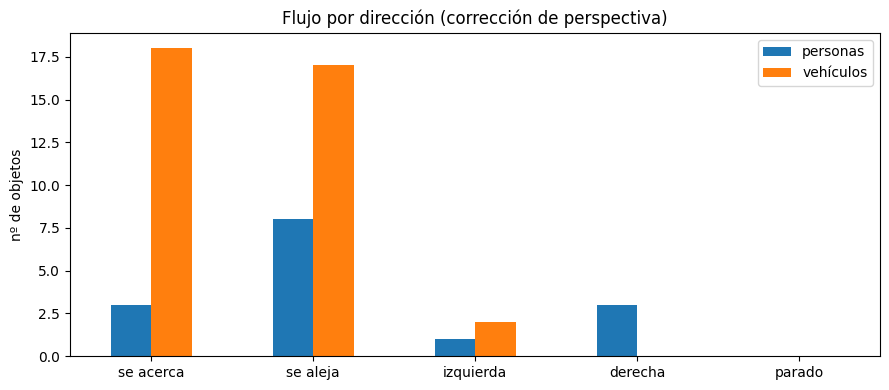

In [23]:
# flujo por direcciones con corrección de perspectiva
DIRECCIONES = ["se acerca", "se aleja", "izquierda", "derecha", "parado"]

flujo = Counter()
for t in contados:
    grupo = "personas" if clase_track[t] == CLASE_PERSONA else "vehículos"
    flujo[(grupo, direccion(tramos[t]))] += 1

tabla_flujo = pd.Series(flujo).unstack(fill_value=0).reindex(columns=DIRECCIONES, fill_value=0)
print(tabla_flujo.to_string())
tabla_flujo.T.plot(kind="bar", figsize=(9, 4), title="Flujo por dirección (corrección de perspectiva)")
plt.ylabel("nº de objetos"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(BASE / "resultados" / "flujo.png", dpi=120); plt.show()

In [24]:
# CSV
filas = []
for d in detecciones:
    if d["id"] not in contados:
        continue
    if d["mat"] is not None:
        cm, mx1, my1, mx2, my2 = d["mat"]
        hay, texto = 1, texto_id.get(d["id"], "")
    else:
        cm = mx1 = my1 = mx2 = my2 = ""
        hay, texto = 0, ""
    filas.append({
        "fotograma": d["fotograma"] * SALTO, # índice real del fotograma en el vídeo original
        "tipo_objeto": CLASES[clase_track[d["id"]]],
        "confianza": d["confianza"],
        "identificador_tracking": d["id"],
        "x1": d["x1"], "y1": d["y1"], "x2": d["x2"], "y2": d["y2"],
        "matricula_en_su_caso": hay, "confianza_matricula": cm,
        "mx1": mx1, "my1": my1, "mx2": mx2, "my2": my2,
        "texto_matricula": texto,
    })
pd.DataFrame(filas).to_csv(BASE / "resultado.csv", index=False)
print("resultado.csv:", len(filas), "filas")


# resultado y anonimizado
def etiqueta(img, texto, x, y, fondo, color_texto=(255, 255, 255), escala=0.5):
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 1)
    x, y = max(0, x), max(th + 4, y)
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + base - 2), fondo, -1)
    cv2.putText(img, texto, (x + 2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, escala, color_texto, 1, cv2.LINE_AA)

def desenfocar(img, x1, y1, x2, y2):
    x1, y1, x2, y2 = max(int(x1), 0), max(int(y1), 0), min(int(x2), img.shape[1]), min(int(y2), img.shape[0])
    if x2 - x1 < 2 or y2 - y1 < 2:
        return
    reg = img[y1:y2, x1:x2]
    img[y1:y2, x1:x2] = cv2.GaussianBlur(reg, (0, 0), max(reg.shape[:2]) / 4)

def anonimizar(img, dets):
    """Se desenfocan TODAS las detecciones (no sólo las contadas) ya que una persona sin contar también es identificable"""
    for d in dets:
        es_persona = d["tipo"] == CLASE_PERSONA or clase_track.get(d["id"]) == CLASE_PERSONA
        if MODO_ANON == "completo":
            desenfocar(img, d["x1"], d["y1"], d["x2"], d["y2"])
        elif es_persona:
            desenfocar(img, d["x1"], d["y1"], d["x2"], d["y1"] + 0.3 * (d["y2"] - d["y1"]))     # 30 % superior = cabeza
        elif d["mat"] is not None:
            desenfocar(img, *d["mat"][1:])

def dibujar(img, dets):
    for d in dets:
        if d["id"] not in contados:
            continue
        es_persona = clase_track[d["id"]] == CLASE_PERSONA
        color = (0, 200, 0) if es_persona else (255, 140, 0)
        cv2.rectangle(img, (d["x1"], d["y1"]), (d["x2"], d["y2"]), color, 2)
        etiqueta(img, f"{CLASES[clase_track[d['id']]]} {d['id']}", d["x1"], d["y1"] - 2, color)
        if d["mat"] is not None and not (ANONIMIZAR and img is frame_anon):
            _, mx1, my1, mx2, my2 = d["mat"]
            cv2.rectangle(img, (mx1, my1), (mx2, my2), (0, 255, 255), 2)
            if d["id"] in texto_id:
                etiqueta(img, texto_id[d["id"]], mx1, my1 - 2, (0, 255, 255), color_texto=(0, 0, 0), escala=0.7)

por_frame = defaultdict(list)
for d in detecciones:
    por_frame[d["fotograma"]].append(d)

SALIDA_LOCAL, ANON_LOCAL = WORK / "resultado.mp4", WORK / "resultado_anonimizado.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(str(SALIDA_LOCAL), fourcc, FPS / SALTO, (ANCHO, ALTO))
out_anon = cv2.VideoWriter(str(ANON_LOCAL), fourcc, FPS / SALTO, (ANCHO, ALTO)) if ANONIMIZAR else None
frame_anon = None
vistos, n, idx = set(), 0, -1
cap = cv2.VideoCapture(str(VIDEO_LOCAL))
while True:
    ok, frame = cap.read()
    if not ok:
        break
    idx += 1
    if idx % SALTO != 0:
        continue
    if LIMITE and n >= LIMITE:
        break
    dets = por_frame.get(n, [])
    frame_anon = frame.copy() if ANONIMIZAR else None
    if ANONIMIZAR:
        anonimizar(frame_anon, dets)
    dibujar(frame, dets)
    vistos.update(d["id"] for d in dets if d["id"] in contados)
    nper = sum(1 for t in vistos if clase_track[t] == CLASE_PERSONA)
    nveh = len(vistos) - nper
    nmat = sum(1 for t in vistos if t in texto_id)
    cabecera = f"Personas: {nper}  Vehiculos: {nveh}  Matriculas leidas: {nmat}"
    etiqueta(frame, cabecera, 10, 30, (0, 0, 0), escala=0.8)
    out.write(frame)
    if ANONIMIZAR:
        dibujar(frame_anon, dets)
        etiqueta(frame_anon, cabecera, 10, 30, (0, 0, 0), escala=0.8)
        out_anon.write(frame_anon)
    n += 1
cap.release()
out.release()
shutil.copy2(SALIDA_LOCAL, BASE / "resultado.mp4")
if ANONIMIZAR:
    out_anon.release()
    shutil.copy2(ANON_LOCAL, BASE / "resultado_anonimizado.mp4")
print("Vídeos guardados en", BASE)

# resumen en json
resumen_video = {
    "fotogramas_leidos": idx + 1, "fotogramas_procesados": n_frame + 1, "salto": SALTO,
    "segundos_pasada": round(T_PASADA, 1), "fps_procesado": round((n_frame + 1) / T_PASADA, 2),
    "identificadores_sin_filtrar": len(tramos), "objetos_contados": dict(conteo),
    "vehiculos_con_matricula_detectada": len(con_matricula), "vehiculos_con_texto_valido": len(texto_id),
    "flujo": {g: {d: int(tabla_flujo.loc[g, d]) if g in tabla_flujo.index else 0 for d in DIRECCIONES} for g in ("personas", "vehículos")},
    "detector_matriculas": ELEGIDO, "ocr_video": OCR_VIDEO, "lecturas": {str(t): txt for t, txt in sorted(texto_id.items())},
}
json.dump(resumen_video, open(BASE / "resultados" / "resumen_video.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
print(json.dumps(resumen_video, indent=1, ensure_ascii=False)[:1500])

resultado.csv: 9092 filas
Vídeos guardados en /content/drive/MyDrive/VC_P4
{
 "fotogramas_leidos": 2832,
 "fotogramas_procesados": 2832,
 "salto": 1,
 "segundos_pasada": 308.2,
 "fps_procesado": 9.19,
 "identificadores_sin_filtrar": 268,
 "objetos_contados": {
  "persona": 15,
  "autobus": 1,
  "coche": 33,
  "moto": 2,
  "bicicleta": 1
 },
 "vehiculos_con_matricula_detectada": 32,
 "vehiculos_con_texto_valido": 2,
 "flujo": {
  "personas": {
   "se acerca": 3,
   "se aleja": 8,
   "izquierda": 1,
   "derecha": 3,
   "parado": 0
  },
  "vehículos": {
   "se acerca": 18,
   "se aleja": 17,
   "izquierda": 2,
   "derecha": 0,
   "parado": 0
  }
 },
 "detector_matriculas": "RT-DETR-L",
 "ocr_video": [
  "smolvlm",
  "easyocr_filtrado"
 ],
 "lecturas": {
  "516": "1770JWG",
  "621": "1965KBP"
 }
}


## Validación manual de las lecturas del vídeo
Las matrículas del vídeo son pequeñas y borrosas, y un VLM puede **inventar** cifras. Calcula el acierto de la lectura final y de **cada OCR sobre recortes reales del vídeo** (una comparativa mucho más relevante que la de las fotos limpias).

In [26]:
# ids (de la cuadrícula) -> texto real, sólo los que puedas leer con seguridad
verdad_video = {621: "1965KBP", 516: "1770JYG", 589: "7339LGG"}

if verdad_video:
    filas = []
    for tid, real in verdad_video.items():
        real = normalizar(real)
        final = texto_id.get(tid, "")
        fila = {"id": tid, "real": real, "final": final, "final_ok": final == real}
        for nm in OCR_VIDEO:
            lec = [t for t in lecturas.get(tid, {}).get(nm, []) if es_valida(t)]
            top = Counter(lec).most_common(1)[0][0] if lec else ""
            fila[nm] = top
            fila[nm + "_ok"] = top == real
        filas.append(fila)
    df_val = pd.DataFrame(filas)
    df_val.to_csv(BASE / "resultados" / "validacion_video.csv", index=False)
    print(df_val.to_string(index=False))
    print(f"\nAcierto de la lectura final: {df_val['final_ok'].mean():.0%} ({int(df_val['final_ok'].sum())}/{len(df_val)})")
    for nm in OCR_VIDEO:
        print(f"Acierto de {nm}: {df_val[nm + '_ok'].mean():.0%}")
else:
    print("Rellena verdad_video para medir el acierto real en el vídeo")

 id    real   final  final_ok smolvlm  smolvlm_ok easyocr_filtrado  easyocr_filtrado_ok
621 1965KBP 1965KBP      True 1965KBP        True          1965KBP                 True
516 1770JYG 1770JWG     False 1770JWG       False                                 False
589 7339LGG             False 7358LCS       False                                 False

Acierto de la lectura final: 33% (1/3)
Acierto de smolvlm: 33%
Acierto de easyocr_filtrado: 33%


## Comprimir los vídeos ya que GitHub no admite archivos de más de 100 MB

In [27]:
for nombre in ["resultado"] + (["resultado_anonimizado"] if ANONIMIZAR else []):
    destino = WORK / f"{nombre}_comprimido.mp4"
    subprocess.run(["ffmpeg", "-y", "-i", str(BASE / f"{nombre}.mp4"), "-vcodec", "libx264", "-crf", "28", "-preset", "fast",
                    "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(destino)], check=True, capture_output=True)
    shutil.copy2(destino, BASE / f"{nombre}_comprimido.mp4")
    print(f"{nombre}_comprimido.mp4: {(BASE / f'{nombre}_comprimido.mp4').stat().st_size / 1e6:.1f} MB")

resultado_comprimido.mp4: 22.5 MB
resultado_anonimizado_comprimido.mp4: 22.4 MB
